<a href="https://colab.research.google.com/github/jacktonomondi439-alt/-CIS-221-SEPT-DEC-2025-/blob/main/AI_DISEASE_DETECTOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!pip install -q transformers datasets evaluate accelerate torchvision scikit-learn seaborn matplotlib huggingface_hub gradio

In [24]:
from huggingface_hub import login

login()

In [29]:
from datasets import load_dataset

print("Downloading plant disease dataset from Hugging Face...")

# Use the full official path
dataset = load_dataset("AI-Lab-Makerere/beans")

# Extract the disease classes
labels = dataset["train"].features["labels"].names
id2label = {i: label for i, label in enumerate(labels)}
label2id = {label: i for i, label in enumerate(labels)}

print(f"\n✅ Success! Loaded {len(labels)} classes:")
for idx, name in id2label.items():
    print(f"  Class {idx}: {name}")

print("\nDataset splits:")
print(dataset)

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]


✅ Success! Loaded 3 classes:
  Class 0: angular_leaf_spot
  Class 1: bean_rust
  Class 2: healthy

Dataset splits:
DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})


In [30]:
import torch
from torchvision.transforms import (
    Compose,
    Resize,
    RandomHorizontalFlip,
    RandomRotation,
    ToTensor,
    Normalize
)
from transformers import AutoImageProcessor

MODEL_CHECKPOINT = "google/mobilenet_v2_1.0_224"
image_processor = AutoImageProcessor.from_pretrained(MODEL_CHECKPOINT)

normalize = Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
size = (image_processor.size["height"], image_processor.size["width"])

# Augmentation for training
train_transforms = Compose([
    Resize(size),
    RandomHorizontalFlip(p=0.5),
    RandomRotation(degrees=15),
    ToTensor(),
    normalize,
])

# Validation/test transforms
val_transforms = Compose([
    Resize(size),
    ToTensor(),
    normalize,
])

def preprocess_train(batch):
    batch["pixel_values"] = [train_transforms(img.convert("RGB")) for img in batch["image"]]
    return batch

def preprocess_val(batch):
    batch["pixel_values"] = [val_transforms(img.convert("RGB")) for img in batch["image"]]
    return batch

dataset["train"].set_transform(preprocess_train)
dataset["validation"].set_transform(preprocess_val)
dataset["test"].set_transform(preprocess_val)

print("Image preprocessing set up successfully!")

Image preprocessing set up successfully!


In [31]:
import evaluate
import numpy as np
from transformers import AutoModelForImageClassification

# Load MobileNetV2 with our custom plant disease output classes
model = AutoModelForImageClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, true_labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=preds, references=true_labels)

def collate_fn(batch):
    pixel_values = torch.stack([x["pixel_values"] for x in batch])
    batch_labels = torch.tensor([x["labels"] for x in batch])
    return {"pixel_values": pixel_values, "labels": batch_labels}

print("Model and metrics ready for training!")

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1001`.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

[transformers] MobileNetV2ForImageClassification LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001, 1280]) vs model:torch.Size([3, 1280])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001]) vs model:torch.Size([3])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model and metrics ready for training!


In [38]:
import torch
import evaluate
import numpy as np
from PIL import Image
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    TrainingArguments,
    Trainer
)

# 1. Image processor and normalization
MODEL_CHECKPOINT = "google/mobilenet_v2_1.0_224"
image_processor = AutoImageProcessor.from_pretrained(MODEL_CHECKPOINT)

normalize = Normalize(
    mean=image_processor.image_mean,
    std=image_processor.image_std
)

clean_transforms = Compose([
    Resize((224, 224)),
    ToTensor(),
    normalize
])

# 2. Return ONLY pixel_values and labels
def transform(batch):
    return {
        "pixel_values": [clean_transforms(img.convert("RGB")) for img in batch["image"]],
        "labels": batch["labels"]
    }

dataset["train"].set_transform(transform)
dataset["validation"].set_transform(transform)
dataset["test"].set_transform(transform)

# 3. Stack numeric tensors only
def collate_fn(batch):
    pixel_values = torch.stack([x["pixel_values"] for x in batch])
    labels = torch.tensor([x["labels"] for x in batch], dtype=torch.long)
    return {"pixel_values": pixel_values, "labels": labels}

# 4. Model
model = AutoModelForImageClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# 5. Accuracy metric
accuracy_metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    predictions, true_labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=preds, references=true_labels)

# 6. Training setup WITH remove_unused_columns=False
training_args = TrainingArguments(
    output_dir="./plant_disease_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=15,
    fp16=torch.cuda.is_available(),
    remove_unused_columns=False,   # 👈 THIS PREVENTS KeyError: 'image'
    push_to_hub=False
)

# 7. Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
)

print("\n🚀 Starting training! The progress bar will start now:")
trainer.train()

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1001`.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

[transformers] MobileNetV2ForImageClassification LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001, 1280]) vs model:torch.Size([3, 1280])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001]) vs model:torch.Size([3])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.



🚀 Starting training! The progress bar will start now:


Epoch,Training Loss,Validation Loss,Accuracy
1,0.505122,0.440679,0.902256
2,0.287105,0.271707,0.917293
3,0.140301,0.207076,0.939850


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=195, training_loss=0.373997224905552, metrics={'train_runtime': 43.0475, 'train_samples_per_second': 72.06, 'train_steps_per_second': 4.53, 'total_flos': 6241226795274240.0, 'train_loss': 0.373997224905552, 'epoch': 3.0})

In [39]:
trainer.push_to_hub("Completed plant disease model")
image_processor.push_to_hub(REPO_NAME)

print(f"Awesome! Your model is now live on Hugging Face at: https://huggingface.co/{REPO_NAME}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Awesome! Your model is now live on Hugging Face at: https://huggingface.co/jackton439/plant-disease-mobilenet


Final Test Accuracy: 91.41%


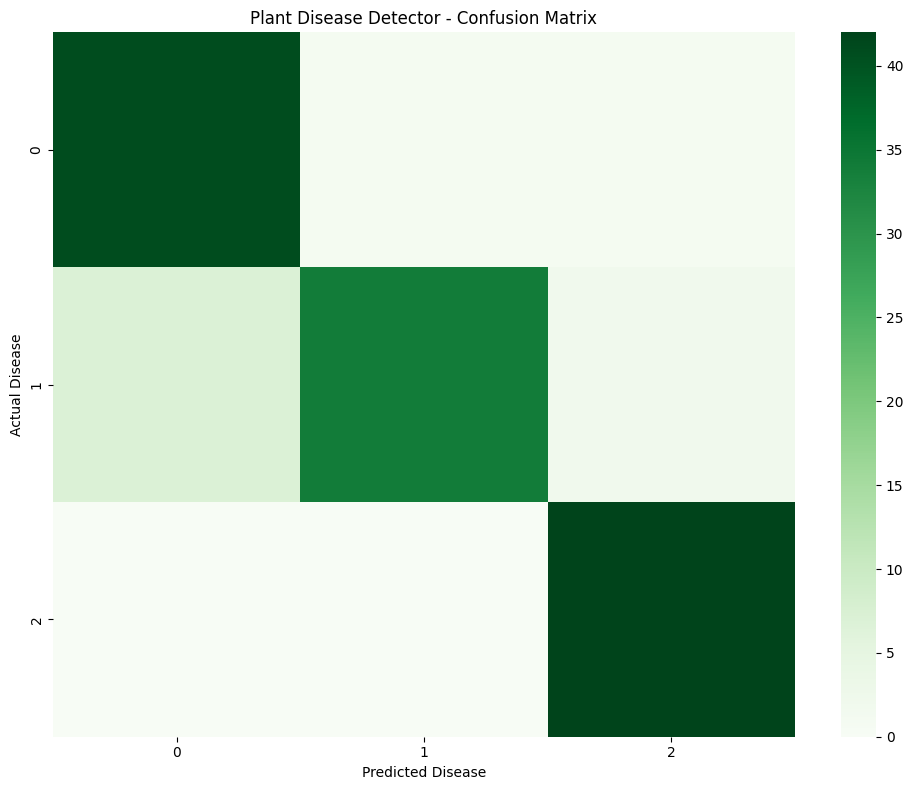

Chart saved as confusion_matrix.png. You can download it from the left file drawer!


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

predictions_output = trainer.predict(dataset["test"])
y_preds = np.argmax(predictions_output.predictions, axis=1)
y_true = predictions_output.label_ids

print(f"Final Test Accuracy: {predictions_output.metrics['test_accuracy'] * 100:.2f}%")

# Generate chart
cm = confusion_matrix(y_true, y_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap="Greens")
plt.title("Plant Disease Detector - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Chart saved as confusion_matrix.png. You can download it from the left file drawer!")